In [668]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
import pandas as pd


# Telco Customer Churn

## The dataset

`telco_churn.csv` is IBM's sample telecom dataset. Each row is one customer of a fictional phone and internet company, and the columns describe who they are, which services they bought, how they are billed, and whether they left.

**7043 rows, 21 columns.** The target is `Churn`, so this is a binary classification problem. 26.5% of customers churned, which makes the classes imbalanced at roughly 2.8 to 1.

`customerID` is a unique identifier with 7043 distinct values and carries no information about behaviour, so it is dropped. That leaves 19 usable features.

## The features

**Who the customer is**

| Feature | Values | Meaning |
|---|---|---|
| `gender` | Female, Male | |
| `SeniorCitizen` | 0, 1 | 1 if the customer is a senior citizen (16.2% of rows). Stored as an integer but it is categorical |
| `Partner` | Yes, No | Whether the customer has a partner |
| `Dependents` | Yes, No | Whether the customer has dependents, such as children |

**Phone services**

| Feature | Values | Meaning |
|---|---|---|
| `PhoneService` | Yes, No | Whether the customer has a phone line |
| `MultipleLines` | Yes, No, No phone service | Whether they have more than one line. The third level only occurs when `PhoneService` is No |

**Internet services**

| Feature | Values | Meaning |
|---|---|---|
| `InternetService` | DSL, Fiber optic, No | Which internet product they bought |
| `OnlineSecurity` | Yes, No, No internet service | Security add-on |
| `OnlineBackup` | Yes, No, No internet service | Backup add-on |
| `DeviceProtection` | Yes, No, No internet service | Device protection add-on |
| `TechSupport` | Yes, No, No internet service | Technical support add-on |
| `StreamingTV` | Yes, No, No internet service | TV streaming |
| `StreamingMovies` | Yes, No, No internet service | Movie streaming |

The six add-on columns all use `No internet service` for exactly the same 1526 customers, which are the ones with `InternetService = No`.

**Account and billing**

| Feature | Values | Meaning |
|---|---|---|
| `tenure` | 0 to 72 | Months the customer has been with the company |
| `Contract` | Month-to-month, One year, Two year | Contract length. This one has a natural order |
| `PaperlessBilling` | Yes, No | |
| `PaymentMethod` | Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic) | How they pay. No natural order |
| `MonthlyCharges` | 18.25 to 118.75 | Amount billed per month |
| `TotalCharges` | 18.80 to 8684.80 | Total billed so far. Stored as text in the raw file |

**Target**

| Feature | Values | Meaning |
|---|---|---|
| `Churn` | Yes, No | Whether the customer left. Converted to 1/0 with Yes = 1 |


## 1. Exploratory Data Analysis

In [669]:
dataset = pd.read_csv("telco_churn.csv")
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [670]:
dataset.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Target balance

26.5% of customers churned. Predicting "no churn" for everyone gives 73.5% accuracy and zero recall, so that is the baseline every model has to beat, and the reason accuracy on its own is not enough here.

In [671]:
#Target balance
dataset['Churn'].value_counts(normalize=True)


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [672]:
#Converting churn to 1/0
#Yes = 1 so that recall answeres "What fraction of churners did i catch?"
dataset['Churn'] = (dataset['Churn'] == 'Yes').astype(int)

In [673]:
#Dropping customerID
dataset = dataset.drop('customerID', axis=1)
dataset.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Missing values

`isna()` returns 0 which is misleading. `TotalCharges` is stored as text and 11 rows contain a blank space instead of a number, so pandas counts them as present. Converting with `errors='coerce'` turns those blanks into real NaN, and then the 11 show up.


In [674]:
dataset.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [675]:
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')

In [676]:
dataset.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [677]:
#Showing how many nan values there are in TotalCharges
dataset['TotalCharges'].isna().sum()


np.int64(11)

### Numeric features

There are only three real numeric columns: `tenure`, `MonthlyCharges` and `TotalCharges`. `SeniorCitizen` and `Churn` also show up in `describe()` but both are categorical, they are just stored as integers.

`MonthlyCharges` has a big spike at around $20, which is around 1400 customers. I check below whether this group is the customers with no `InternetService`, since that would explain the low charge.

Note that the spike means the distribution is bimodal rather than skewed. A skew number cannot describe a distribution with two peaks, so it reports close to zero here even though the shape is clearly not symmetric. `tenure` has the same problem, it is high at both ends and low in the middle.

In [678]:
dataset.describe()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000
mean,0.162147,32.371149,64.761692,2283.300441,0.265370
std,0.368612,24.559481,30.090047,2266.771362,0.441561
min,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,9.000000,35.500000,401.450000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000
75%,0.000000,55.000000,89.850000,3794.737500,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


array([[<Axes: title={'center': 'SeniorCitizen'}>,
        <Axes: title={'center': 'tenure'}>],
       [<Axes: title={'center': 'MonthlyCharges'}>,
        <Axes: title={'center': 'TotalCharges'}>],
       [<Axes: title={'center': 'Churn'}>, <Axes: >]], dtype=object)

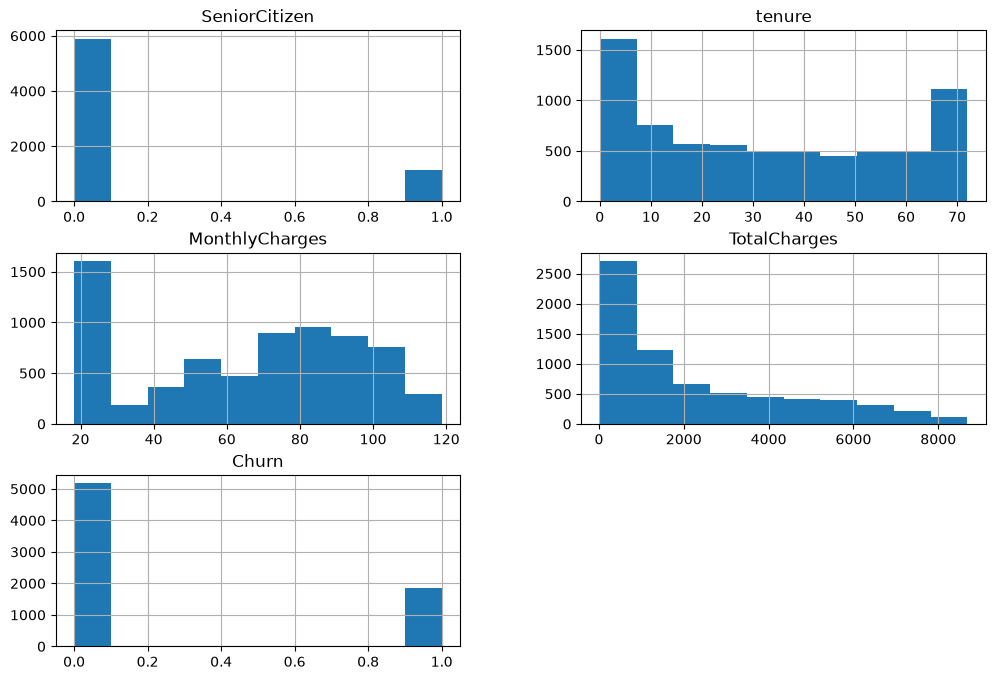

In [679]:

dataset.hist(figsize=(12, 8))

In [680]:
dataset.groupby('InternetService')['MonthlyCharges'].describe()



,count,mean,std,min,25%,50%,75%,max
InternetService,,,,,,,,
DSL,2421.0,58.102169,16.259522,23.45,46.20,56.150,69.90,94.80
Fiber optic,3096.0,91.500129,12.663039,67.75,80.55,91.675,101.15,118.75
No,1526.0,21.079194,2.164221,18.25,19.70,20.150,20.90,26.90


The table confirms the price bands are almost separate:

| InternetService | range | count |
|---|---|---|
| No | $18.25 to $26.90 | 1526 |
| DSL | $23.45 to $94.80 | 2421 |
| Fiber optic | $67.75 to $118.75 | 3096 |

A `MonthlyCharges` below $27 means no internet almost without exception. So this column is partly an encoding of which product the customer bought, not only what they pay.

### Churn by internet service

Next I look at who churns, split by `InternetService`. Fiber optic customers churn the most at 42%, and they are also the ones paying the most at $91 on average. The overall churn rate is 26.5%.

That is a problem for interpretation. If a model says high `MonthlyCharges` predicts churn, I cannot tell whether price drives churn or whether fiber optic does and price just follows along. Both give identical predictions but mean different things. One says lower the price, the other says fix the fiber service.

In [681]:
dataset.groupby('InternetService')['Churn'].mean()


InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64

### Untangling it by stratifying

Stratifying means looking at the relationship inside each service type, so service type is held constant. If churn still rises with price inside the fiber group and inside the DSL group, then price matters on its own. If it does not, then service type is the whole story and price was only a proxy.

The result reverses. Inside DSL, churn falls from 36% to 2% as price rises. Inside fiber optic it falls from 59% to 34%. So within a service type, paying more goes with churning less, which is the opposite of the aggregate.

This is Simpson's Paradox, where a relationship in the aggregate reverses inside every subgroup.

I would not say that price causes loyalty. Inside a service type a higher bill mostly means the customer bought more add-on services and signed a longer contract, and those are what go with lower churn. The useful conclusion is that the raw reading of "expensive customers churn" is wrong, and service type was doing the work.

One caution on the table: the DSL $89.85 to $118.75 cell only has 50 customers, so its 2% rate rests on very few people.

In [682]:
dataset.groupby(['InternetService', pd.qcut(dataset.MonthlyCharges, 4)])['Churn'].agg(['size', 'mean'])

size      mean
InternetService MonthlyCharges                 
DSL             (18.249, 35.5]    236  0.360169
                (35.5, 70.35]    1605  0.211215
                (70.35, 89.85]    530  0.064151
                (89.85, 118.75]    50  0.020000
Fiber optic     (35.5, 70.35]     161  0.590062
                (70.35, 89.85]   1227  0.509372
                (89.85, 118.75]  1708  0.337822
No              (18.249, 35.5]   1526  0.074050

### Churn rate for every categorical feature

Since `Churn` is 0/1, its mean within a group is the churn rate. I print `size` next to it because a rate computed from a handful of customers is noise.

The ones that stand out:

| Feature | Spread |
|---|---|
| `Contract` | 42.7% month-to-month vs 2.8% two year |
| `PaymentMethod` | 45.3% electronic check vs 15.2% credit card |
| `OnlineSecurity` | 41.8% without vs 14.6% with |
| `TechSupport` | 41.6% without vs 15.2% with |
| `gender` | 26.9% vs 26.2%, no signal at all |

`Contract` is the strongest single predictor in the dataset. `gender` separating nothing is also worth reporting, since a feature carrying no information is a finding.

In [683]:
#Looking at all the features
cats = list(dataset.select_dtypes(exclude='number').columns) + ['SeniorCitizen']

for col in cats:
    print(dataset.groupby(col)['Churn'].agg(['size', 'mean']).sort_values('mean').round(3))
    print()


        size   mean
gender             
Male    3555  0.262
Female  3488  0.269

         size   mean
Partner             
Yes      3402  0.197
No       3641  0.330

            size   mean
Dependents             
Yes         2110  0.155
No          4933  0.313

              size   mean
PhoneService             
No             682  0.249
Yes           6361  0.267

                  size   mean
MultipleLines                
No phone service   682  0.249
No                3390  0.250
Yes               2971  0.286

                 size   mean
InternetService             
No               1526  0.074
DSL              2421  0.190
Fiber optic      3096  0.419

                     size   mean
OnlineSecurity                  
No internet service  1526  0.074
Yes                  2019  0.146
No                   3498  0.418

                     size   mean
OnlineBackup                    
No internet service  1526  0.074
Yes                  2429  0.215
No                   3088  0.399

   

<Axes: title={'center': 'tenure'}, xlabel='Churn'>

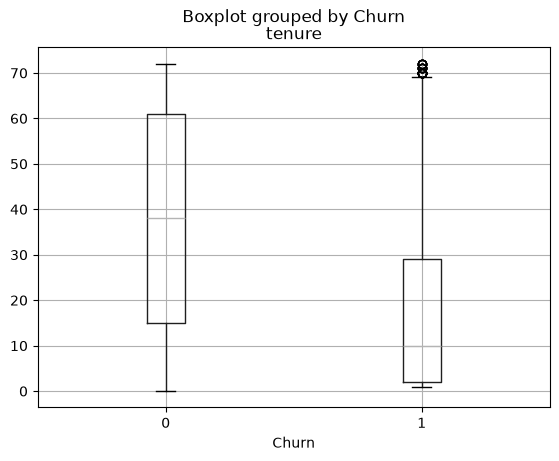

In [684]:
dataset.boxplot(column='tenure', by='Churn')


`tenure` separates the two classes clearly. Customers who churn have much shorter tenure, which fits the U-shape in the histogram: a lot of recent signups and a lot of long-term survivors.

`tenure`, `Contract`, `MonthlyCharges` and the number of add-on services all move together, so they should be read as one cluster rather than four independent signals. That matters when I look at feature importances later.

In [685]:
dataset.mode()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.05,20.2,0


In [686]:
dataset.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Correlation analysis on numeric features


In [687]:
correlation = dataset.corr(numeric_only=True)
correlation.style.background_gradient(cmap='coolwarm')

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.000000,0.016567,0.220173,0.102411,0.150889
tenure,0.016567,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.102411,0.825880,0.651065,1.000000,-0.199484
Churn,0.150889,-0.352229,0.193356,-0.199484,1.000000


## 2. Data Processing

The EDA produced decisions, but most of them have a defensible alternative. Instead of picking one of each I list them here and let the hyperparameter search compare them.

| Decision | Option A | Option B |
|---|---|---|
| `TotalCharges` missing | fill with 0 | median |
| `No internet service` | collapse to `No` | keep as its own level |
| `Contract` | ordinal | one-hot |
| Other categoricals | one-hot | ordinal |
| Numeric scaling | standard | min-max, or none |

Anything that learns from the data has to be fit on training folds only, so these steps go inside a pipeline rather than being applied to the dataframe here.

### Encoding

16 of the 19 features are categorical. I group the columns by what they need.

**Binary Yes/No** (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, and `gender`) map straight to 1/0. With only two levels, ordinal encoding and one-hot with `drop_first` produce an identical column, so there is nothing to choose between them.

**The six add-on columns and `MultipleLines`** have a third level, `No internet service` or `No phone service`. I confirmed in the EDA that these match `InternetService == No` and `PhoneService == No` exactly, for all 1526 and all 682 rows. So collapsing them to a plain `No` loses no information, because the other column already says it. Keeping them produces six one-hot columns that perfectly duplicate `InternetService_No`.

**`Contract`** has a real order: month-to-month, one year, two year. Ordinal encoding is defensible here and keeps one column instead of three.

**`InternetService` and `PaymentMethod`** have no natural order, so one-hot. Giving `PaymentMethod` the values 0 to 3 would claim that electronic check is less than mailed check, which is invented.

I write this as a function with the four alternatives as arguments, so the choices stay visible and can be compared later instead of than being baked in.

In [688]:
# Manual encoding. Each argument is one of the processing alternatives
# from the EDA, so the choices are explicit rather than baked in.

BINARY = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
SERVICE = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
           'TechSupport', 'StreamingTV', 'StreamingMovies']
CONTRACT_ORDER = {'Month-to-month': 0, 'One year': 1, 'Two year': 2}


def encode(df, collapse_no_service=True, contract_ordinal=True, drop_first=False):
    df = df.copy()

    # binary Yes/No to 1/0
    for col in BINARY:
        df[col] = (df[col] == 'Yes').astype(int)
    df['gender'] = (df['gender'] == 'Male').astype(int)

    # the redundant third level, already shown to duplicate
    #    InternetService == No and PhoneService == No
    if collapse_no_service:
        for col in SERVICE:
            df[col] = (df[col] == 'Yes').astype(int)
        df['MultipleLines'] = (df['MultipleLines'] == 'Yes').astype(int)

    # Contract has a real order, so ordinal is an option
    if contract_ordinal:
        df['Contract'] = df['Contract'].map(CONTRACT_ORDER)

    # one-hot whatever categorical columns are left
    return pd.get_dummies(df, drop_first=drop_first, dtype=int)


In [689]:
# How many features does each configuration produce?
features = dataset.drop('Churn', axis=1)

for collapse in [True, False]:
    for ordinal in [True, False]:
        for first in [False, True]:
            n = encode(features, collapse, ordinal, first).shape[1]
            print(f'collapse={collapse!s:<5} contract_ordinal={ordinal!s:<5} '
                  f'drop_first={first!s:<5} -> {n} columns')


collapse=True  contract_ordinal=True  drop_first=False -> 24 columns
collapse=True  contract_ordinal=True  drop_first=True  -> 22 columns
collapse=True  contract_ordinal=False drop_first=False -> 26 columns
collapse=True  contract_ordinal=False drop_first=True  -> 23 columns
collapse=False contract_ordinal=True  drop_first=False -> 38 columns
collapse=False contract_ordinal=True  drop_first=True  -> 29 columns
collapse=False contract_ordinal=False drop_first=False -> 40 columns
collapse=False contract_ordinal=False drop_first=True  -> 30 columns


In [690]:
# Default configuration, and a check that nothing categorical survived
encoded = encode(features)
print('shape:', encoded.shape)
print('non-numeric columns left:', list(encoded.select_dtypes(exclude='number').columns))
encoded.head()


shape: (7043, 24)
non-numeric columns left: []


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService_DSL,InternetService_Fiber optic,InternetService_No,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,1,29.85,29.85,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,0,56.95,1889.50,1,0,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,1,53.85,108.15,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,0,42.30,1840.75,1,0,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,1,70.70,151.65,0,1,0,0,0,1,0


The eight configurations range from 22 to 40 columns, so these choices nearly double the width of the feature matrix depending on how they are set. That alone is a reason to compare them rather than pick one.

Note that `encode()` runs on the whole dataframe here, which is fine for looking at the output but not for training. `pd.get_dummies` learns which categories exist from whatever it is given, so applying it before the split lets information about the test set influence the feature columns. It can also produce different columns for train and test if a rare category appears in only one of them, which then breaks `predict` on a shape mismatch.

The pipeline version below uses `OneHotEncoder` with `handle_unknown='ignore'` instead. It remembers the categories from the training fit and is refit inside every cross-validation fold, which removes both problems and makes these four choices tunable.

### Train and test split

60/40, stratified on `Churn` so both sets keep the 26.5% rate, with a fixed `random_state` so the split is reproducible.

There is no separate validation set because `GridSearchCV` cross validates inside the trainval portion. The test set is not touched until the final evaluation.

In [691]:
#global random state
global_random_state = 13

In [692]:
#Spliting data 
dataset_trainval, dataset_test = train_test_split(dataset, test_size=0.4, shuffle=True, random_state=global_random_state ,stratify=dataset['Churn'])
features_trainval = dataset_trainval.drop('Churn', axis=1)
features_test = dataset_test.drop('Churn', axis=1)
targets_trainval = dataset_trainval['Churn']
targets_test = dataset_test['Churn']

print(features_trainval.shape)
print(features_test.shape)



(4225, 19)
(2818, 19)


### Missing values in `TotalCharges`

As found in the EDA, `TotalCharges` has 11 missing values and every one of them has `tenure = 0`, which does not happen anywhere else. The value is missing if and only if the customer has been subscribed for zero months, so these customers have never been billed and there is no total to record.

That is why the imputer fills with 0 by default rather than the median. The median would insert about 2283 for a customer who has paid nothing.

Median imputation stays in the grid as an alternative so the choice is tested and not just assumed.

## 3. Models and Hyperparameter Tuning

### The pipeline

A pipeline chains the preprocessing and the model into one object. `fit` runs every step in order and each step learns from the training data only. `predict` reuses what was learned instead of relearning it. That means a scaler can never see the test set, which was a bug I had in the first assignment.

`ColumnTransformer` routes columns to different treatment: the three numeric columns are imputed and scaled, the 16 categorical ones are encoded.

The numeric branch is itself a `Pipeline` because it needs two steps in order, and the order matters. Imputing after scaling would place the filled value at the mean rather than at zero, which is the opposite of what I argued for above.

`remainder='passthrough'` keeps any column I did not list. Here the two lists already cover all 19, so it changes nothing, but the default is to drop them.

In [693]:
#Pipeline
numeric = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical = [c for c in features_trainval.columns if c not in numeric]

encode = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value=0)), ('scale', StandardScaler())]), numeric), 
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
], remainder='passthrough')

dt_pipe = Pipeline([('encode', encode), ('estimator', DecisionTreeClassifier())])

dt_pipe.get_params()

{'memory': None,
 'steps': [('encode',
   ColumnTransformer(remainder='passthrough',
                     transformers=[('num',
                                    Pipeline(steps=[('impute',
                                                     SimpleImputer(fill_value=0,
                                                                   strategy='constant')),
                                                    ('scale', StandardScaler())]),
                                    ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                   ('cat', OneHotEncoder(handle_unknown='ignore'),
                                    ['gender', 'SeniorCitizen', 'Partner',
                                     'Dependents', 'PhoneService', 'MultipleLines',
                                     'InternetService', 'OnlineSecurity',
                                     'OnlineBackup', 'DeviceProtection',
                                     'TechSupport', 'StreamingTV',
                

### Baseline 1: Decision tree

Two tree parameters, `max_depth` and `min_samples_leaf`, both limiting how far the tree is allowed to grow.

#### The parameter grid

The step names become the keys. `encode__num__impute__strategy` reads as: the step `encode`, its branch `num`, its step `impute`, and the parameter `strategy`. `pipe.get_params()` lists the valid names.

Three of the five entries are processing choices rather than model parameters, and their values are whole objects rather than settings. That is how an encoder or a scaler gets swapped out by the search.

2 x 3 x 2 x 4 x 3 = 144 combinations, each fitted on 5 folds, so 720 fits.

`scoring='f1'` matters here. The default is accuracy, and with 26.5% churn that pushes the search toward the majority class. Optimising accuracy instead picked a shallower tree with recall 0.37 instead of 0.58, at the same accuracy.

In [694]:
#specifiying the parameter grid.
dt_pipe_params = {
    'encode__num__impute__strategy': ['constant', 'median'],
    'encode__num__scale': [StandardScaler(), MinMaxScaler(), 'passthrough'],
     'encode__cat': [OneHotEncoder(handle_unknown='ignore'), 
                    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)],

    'estimator__max_depth': [3, 5, 10, None],
    'estimator__min_samples_leaf': [1, 5, 20],
}

dt_pipe_grid = GridSearchCV(dt_pipe, dt_pipe_params, scoring='f1', n_jobs=-1)
dt_pipe_grid.fit(features_trainval, targets_trainval)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'encode__cat': [OneHotEncoder...nown='ignore'), OrdinalEncode...nown_value=-1)], 'encode__num__impute__strategy': ['constant', 'median'], 'encode__num__scale': [StandardScaler(), MinMaxScaler(), ...], 'estimator__max_depth': [3, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategie

`best_params_` only says which combination came top, never by how much. Averaging each choice over everything else shows what it is actually worth.

In [695]:
dt_pipe_grid.best_params_

{'encode__cat': OneHotEncoder(handle_unknown='ignore'),
 'encode__num__impute__strategy': 'constant',
 'encode__num__scale': StandardScaler(),
 'estimator__max_depth': 5,
 'estimator__min_samples_leaf': 20}

In [696]:
dt_pipe_grid.best_score_

np.float64(0.5790799346189297)

In [697]:
# What is each processing choice actually worth?
# best_params_ reports a winner even when the difference is noise.
results = pd.DataFrame(dt_pipe_grid.cv_results_)

for col in [c for c in results.columns if c.startswith('param_')]:
    print(col.replace('param_encode__', ''))
    print(results.groupby(results[col].map(str))['mean_test_score'].mean().round(4).to_string())
    print()

print('spread across all combinations:', round(results['mean_test_score'].std(), 4))


cat
param_encode__cat
OneHotEncoder(handle_unknown='ignore')                                  0.5431
OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)    0.5359

num__impute__strategy
param_encode__num__impute__strategy
constant    0.5396
median      0.5395

num__scale
param_encode__num__scale
MinMaxScaler()      0.5394
StandardScaler()    0.5396
passthrough         0.5396

param_estimator__max_depth
param_estimator__max_depth
10      0.5503
3       0.5195
5       0.5649
None    0.5235

param_estimator__min_samples_leaf
param_estimator__min_samples_leaf
1     0.5340
20    0.5454
5     0.5392

spread across all combinations: 0.0224


`max_depth` is the only parameter that moves anything. Depth 5 averages 0.5649 against 0.5195 at depth 3 and 0.5232 unrestricted, so the tree underfits at 3 and overfits when left to grow. `min_samples_leaf` follows the same logic from the other side, 20 averages above 1.

The processing choices move almost nothing. Imputation is identical to four decimals, which is expected since 5 missing values out of 4225 cannot shift a metric however they are filled. Scaling spans 0.0007, also expected, because a tree splits on order and scaling does not change the order. Only the encoder is visible at 0.0065, since one-hot lets a split isolate a single category while ordinal forces the tree to work around an invented ordering.

So the three processing options were worth testing and the answer for this model is that they do not matter.  

### Baseline 2: Logistic regression

Same pipeline and the same three processing entries, so the comparison against the tree is fair. Only the estimator and its two parameters change.

`C` is inverse regularisation strength. A small `C` penalises large coefficients harder and pulls the model toward a simpler fit. It acts multiplicatively, which is why the values step by a factor of 10 rather than by a fixed amount.

`class_weight='balanced'` reweights the classes by inverse frequency. It is the same setting that lifted recall on the SGD model in the first assignment.

`max_iter` is raised to 2000 from the default 100, for the reason below.

In [698]:
lr_pipe = Pipeline([('encode', encode), ('estimator', LogisticRegression(max_iter=2000, random_state=global_random_state))])

lr_pipe.get_params()

{'memory': None,
 'steps': [('encode',
   ColumnTransformer(remainder='passthrough',
                     transformers=[('num',
                                    Pipeline(steps=[('impute',
                                                     SimpleImputer(fill_value=0,
                                                                   strategy='constant')),
                                                    ('scale', StandardScaler())]),
                                    ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                   ('cat', OneHotEncoder(handle_unknown='ignore'),
                                    ['gender', 'SeniorCitizen', 'Partner',
                                     'Dependents', 'PhoneService', 'MultipleLines',
                                     'InternetService', 'OnlineSecurity',
                                     'OnlineBackup', 'DeviceProtection',
                                     'TechSupport', 'StreamingTV',
                

In [699]:
#specifiying the parameter grid for logsticRegression.
lr_pipe_params = {
    'encode__num__impute__strategy': ['constant', 'median'],
    'encode__num__scale': [StandardScaler(), MinMaxScaler(), 'passthrough'],
     'encode__cat': [OneHotEncoder(handle_unknown='ignore'), 
                    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)],
    'estimator__C': [0.1, 1, 10],
    'estimator__class_weight': [None, 'balanced']


}
lr_pipe_grid = GridSearchCV(lr_pipe, lr_pipe_params, scoring='f1', n_jobs=-1)
lr_pipe_grid.fit(features_trainval, targets_trainval)


/Users/khalil/uni/T_E_Baseline-Models/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/khalil/uni/T_E_Baseline-Models/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://s

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'encode__cat': [OneHotEncoder...nown='ignore'), OrdinalEncode...nown_value=-1)], 'encode__num__impute__strategy': ['constant', 'median'], 'encode__num__scale': [StandardScaler(), MinMaxScaler(), ...], 'estimator__C': [0.1, 1, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that

#### The convergence warnings

The output above is full of `ConvergenceWarning`, and all of it comes from the `passthrough` combinations. Unscaled, `TotalCharges` runs to 8684 while the one-hot columns are 0 or 1, so the solver cannot pick a step size that suits both and it runs out of iterations before it settles.

Raising `max_iter` to 2000 clears the warning for every scaled combination but not for the unscaled ones. Scaling here is not about what the model is able to learn, it is about whether the solver gets there. A combination that never finished fitting is still scored and can still win, so this is worth fixing rather than suppressing.

In [700]:
#beat params
lr_pipe_grid.best_params_

{'encode__cat': OneHotEncoder(handle_unknown='ignore'),
 'encode__num__impute__strategy': 'constant',
 'encode__num__scale': 'passthrough',
 'estimator__C': 0.1,
 'estimator__class_weight': 'balanced'}

In [701]:
#best score
lr_pipe_grid.best_score_

np.float64(0.6321619081498955)

In [702]:
# What is each processing choice actually worth?
# best_params_ reports a winner even when the difference is noise.
results = pd.DataFrame(lr_pipe_grid.cv_results_)

for col in [c for c in results.columns if c.startswith('param_')]:
    print(col.replace('param_encode__', ''))
    print(results.groupby(results[col].map(str))['mean_test_score'].mean().round(4).to_string())
    print()

print('spread across all combinations:', round(results['mean_test_score'].std(), 4))

cat
param_encode__cat
OneHotEncoder(handle_unknown='ignore')                                  0.6134
OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)    0.6130

num__impute__strategy
param_encode__num__impute__strategy
constant    0.6133
median      0.6131

num__scale
param_encode__num__scale
MinMaxScaler()      0.6095
StandardScaler()    0.6138
passthrough         0.6163

param_estimator__C
param_estimator__C
0.1     0.6099
1.0     0.6143
10.0    0.6154

param_estimator__class_weight
param_estimator__class_weight
balanced    0.6271
nan         0.5994

spread across all combinations: 0.0148


`class_weight` dominates. Balanced averages 0.6271 against 0.5994, a gap of 0.028 that is larger than the encoder, the imputer, the scaler and `C` put together. The `nan` row is `class_weight=None`, which is how Python's `None` prints once it has been grouped.

The processing choices are small again, but not the same as for the tree. Scaling now spans 0.0068 instead of 0.0007, and the encoder has almost stopped mattering, 0.0004 against the tree's 0.0065. That fits how the two models work: a linear model fits one coefficient per column whatever the encoding, while a tree cares whether a category can be isolated in a single split.

`best_params_` picked `C=0.1`, which has the lowest average of the three values. It won inside one particular combination instead of on its own merit, which is the reason for reading the marginal table and not just the winner.

Logistic regression reaches 0.6322 against the decision tree's 0.5791, so the simpler model is ahead by 0.05 F1. That is consistent with a dataset where most features are binary and the signal looks close to additive.

### Advanced 1: Random forest

A collection of decision trees, each grown on a bootstrap sample of the rows and allowed to look at only a random subset of the features at every split. The votes are averaged, which cancels variance that a single tree would keep.

Three parameters are tuned:

- `max_depth`, the same meaning as in the single tree.
- `max_features`, how many features each split may consider. This is what stops the trees from being near copies of each other.
- `class_weight`, carried over because it was the strongest setting in both baselines.

`max_features` stays relative, `'sqrt'`, `'log2'` or `None`, rather than a fixed integer. The grid swaps encoders, so the feature count is 46 under one-hot and 19 under ordinal, and an integer would mean a different fraction in each case.

`random_state` matters here for the first time. Bootstrap sampling and feature subsetting are both random, so the result moves between runs without it.

In [703]:
#RandomForestClassifier
rf_pipe = Pipeline([('encode', encode), ('estimator', RandomForestClassifier(random_state=global_random_state))])

rf_pipe.get_params()

{'memory': None,
 'steps': [('encode',
   ColumnTransformer(remainder='passthrough',
                     transformers=[('num',
                                    Pipeline(steps=[('impute',
                                                     SimpleImputer(fill_value=0,
                                                                   strategy='constant')),
                                                    ('scale', StandardScaler())]),
                                    ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                   ('cat', OneHotEncoder(handle_unknown='ignore'),
                                    ['gender', 'SeniorCitizen', 'Partner',
                                     'Dependents', 'PhoneService', 'MultipleLines',
                                     'InternetService', 'OnlineSecurity',
                                     'OnlineBackup', 'DeviceProtection',
                                     'TechSupport', 'StreamingTV',
                

In [704]:
#specifiying the parameter grid for RandomForestClassifier.
rf_pipe_params = {
    'encode__num__impute__strategy': ['constant', 'median'],
    'encode__num__scale': [StandardScaler(), MinMaxScaler(), 'passthrough'],
     'encode__cat': [OneHotEncoder(handle_unknown='ignore'), 
                    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)],
    'estimator__class_weight': [None, 'balanced'],
    'estimator__max_depth': [3, 5, 10, None],
    'estimator__max_features': ['sqrt', 'log2', None],
    
}
rf_pipe_grid = GridSearchCV(rf_pipe, rf_pipe_params, scoring='f1', n_jobs=-1)
rf_pipe_grid.fit(features_trainval, targets_trainval)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'encode__cat': [OneHotEncoder...nown='ignore'), OrdinalEncode...nown_value=-1)], 'encode__num__impute__strategy': ['constant', 'median'], 'encode__num__scale': [StandardScaler(), MinMaxScaler(), ...], 'estimator__class_weight': [None, 'balanced'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation

In [705]:
#best params
rf_pipe_grid.best_params_

{'encode__cat': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
 'encode__num__impute__strategy': 'constant',
 'encode__num__scale': 'passthrough',
 'estimator__class_weight': 'balanced',
 'estimator__max_depth': 10,
 'estimator__max_features': 'sqrt'}

In [706]:
#best score
rf_pipe_grid.best_score_

np.float64(0.6342217630657571)

In [707]:
# What is each processing choice actually worth?
# best_params_ reports a winner even when the difference is noise.
results = pd.DataFrame(rf_pipe_grid.cv_results_)

for col in [c for c in results.columns if c.startswith('param_')]:
    print(col.replace('param_encode__', ''))
    print(results.groupby(results[col].map(str))['mean_test_score'].mean().round(4).to_string())
    print()

print('spread across all combinations:', round(results['mean_test_score'].std(), 4))

cat
param_encode__cat
OneHotEncoder(handle_unknown='ignore')                                  0.5747
OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)    0.5855

num__impute__strategy
param_encode__num__impute__strategy
constant    0.5801
median      0.5801

num__scale
param_encode__num__scale
MinMaxScaler()      0.5800
StandardScaler()    0.5800
passthrough         0.5803

param_estimator__class_weight
param_estimator__class_weight
balanced    0.6170
nan         0.5431

param_estimator__max_depth
param_estimator__max_depth
10      0.6013
3       0.5543
5       0.5861
None    0.5787

param_estimator__max_features
param_estimator__max_features
log2    0.5750
nan     0.5870
sqrt    0.5782

spread across all combinations: 0.0465


`class_weight` is worth 0.0739, balanced at 0.6170 against 0.5431 for `None`. That is the largest effect of any parameter in this notebook, close to three times what it was worth for logistic regression. Without it the forest votes for the majority class nearly everywhere and recall collapses. Both `nan` rows in the table are `None`.

The encoder preference flipped between the two tree models:

| | one-hot | ordinal |
|---|---|---|
| decision tree | 0.5426 | 0.5361 |
| random forest | 0.5747 | 0.5855 |

`max_features` explains it. One-hot produces 46 columns so `sqrt` draws 6 of them, ordinal produces 19 so `sqrt` draws 4. One-hot spreads a single feature across many mostly empty columns, so a random draw often holds nothing but rare category indicators and the split is wasted. Ordinal keeps one column per feature, so every draw is made of real features.

This only shows up because the processing options stayed in the grid for both models. Which encoding is right depends on the model, which was the argument for tuning it jointly instead of fixing it after the EDA.

`max_depth` peaks at 10 here against 5 for the single tree. A deep tree overfits, but the overfitting is largely independent between trees, so averaging cancels it and the forest can afford the extra depth.

`best_params_` picked `max_features='sqrt'` while `None` has the better average. That is the third time the winner and the marginal disagree, so `best_params_` is better treated as one sample than as a conclusion.

In [708]:
# Is the gap between models larger than the noise around it?
# std_test_score is the spread across the 5 folds, already in cv_results_.
for name, grid in [('Decision tree', dt_pipe_grid),
                   ('Logistic regression', lr_pipe_grid),
                   ('Random forest', rf_pipe_grid)]:
    r = pd.DataFrame(grid.cv_results_)
    best = r.loc[r['rank_test_score'].idxmin()]
    print(f'{name:<22} f1 {best["mean_test_score"]:.4f}   fold std {best["std_test_score"]:.4f}')


Decision tree          f1 0.5791   fold std 0.0276
Logistic regression    f1 0.6322   fold std 0.0092
Random forest          f1 0.6342   fold std 0.0078


The forest leads logistic regression by 0.0020, and the spread across folds is around 0.008 for both. The gap is a quarter of the noise, so the fair reading is that the forest matched the linear baseline rather than beat it.

That is worth stating plainly. A 0.002 difference reported as an improvement would not survive a different split or a different seed.

### Advanced 2: Histogram gradient boosting

The forest grows trees independently and averages them. Boosting grows them one after another, each one fitted to the errors the previous trees left behind. The histogram part is that every numeric feature is bucketed into at most 255 bins up front, which is what keeps a sequential method fast.

Four parameters are tuned:

- `learning_rate`, how much each new tree is allowed to contribute.
- `max_iter`, how many trees are grown.
- `max_leaf_nodes`, the size of each tree. This model grows leaf-wise, splitting wherever the gain is largest rather than level by level, so leaf count is the natural limit instead of `max_depth`.
- `class_weight`, carried over from the other models.

`learning_rate` and `max_iter` are really one knob. Each tree's contribution is multiplied by the rate, so halving the rate roughly doubles the number of trees needed to reach the same fit. Tuning one with the other fixed would just find the edge of the range.

Two changes to the processing block for this model.

`encode__num__scale` is pinned to `'passthrough'`. The runs on the earlier models showed scaling doing nothing, and here it is exactly nothing: this model bins each feature by quantile, and quantiles do not move under a monotonic transform, so all three scalers produce identical bins and identical trees. Leaving three options in the grid would have tripled the runtime to compare values that cannot differ.

`encode__num__impute` now swaps the whole step rather than the `strategy` string, so that `'passthrough'` can be one of the options. This model reads `NaN` natively and sends it down whichever side of a split fits better, so not imputing is an alternative here and not for any of the others.

One thing that could not be used. `HistGradientBoostingClassifier` has a `categorical_features` parameter, set to `'from_dtype'` by default, which looks for pandas categorical columns. `ColumnTransformer` outputs a plain float array with no dtype information, so nothing is detected and all columns are treated as continuous. It could be given an explicit index list instead, but the list would need to be 19 columns long under the ordinal encoder and 46 under one-hot, so it breaks as soon as the grid swaps encoders. The same problem as `max_features` in the forest.

In [709]:
#HistGradientBoostingClassifier
hgb_pipe = Pipeline([('encode', encode), ('estimator', HistGradientBoostingClassifier(random_state=global_random_state))])
hgb_pipe.get_params


<bound method Pipeline.get_params of Pipeline(steps=[('encode',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
      

In [710]:
#specifiying the parameter grid for HistGradientBoostingClassifier.
hgb_pipe_params = {
    'encode__num__impute': ['passthrough',
                        SimpleImputer(strategy='constant', fill_value=0),
                        SimpleImputer(strategy='median')],
    'encode__num__scale': ['passthrough'],
     'encode__cat': [OneHotEncoder(handle_unknown='ignore'), 
                    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)],
    'estimator__learning_rate': [0.05, 0.1, 0.2],
    'estimator__max_iter': [50,100, 200],
    'estimator__max_leaf_nodes': [7, 15, 31],
    'estimator__class_weight': [None, 'balanced'],
}
hgb_pipe_grid = GridSearchCV(hgb_pipe, hgb_pipe_params, scoring='f1', n_jobs=-1)
hgb_pipe_grid.fit(features_trainval, targets_trainval)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'encode__cat': [OneHotEncoder...nown='ignore'), OrdinalEncode...nown_value=-1)], 'encode__num__impute': ['passthrough', SimpleImputer...gy='constant'), ...], 'encode__num__scale': ['passthrough'], 'estimator__class_weight': [None, 'balanced'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation str

In [711]:
hgb_pipe_grid.best_params_

{'encode__cat': OneHotEncoder(handle_unknown='ignore'),
 'encode__num__impute': SimpleImputer(fill_value=0, strategy='constant'),
 'encode__num__scale': 'passthrough',
 'estimator__class_weight': 'balanced',
 'estimator__learning_rate': 0.05,
 'estimator__max_iter': 50,
 'estimator__max_leaf_nodes': 15}

In [712]:
hgb_pipe_grid.best_score_

np.float64(0.6352261981861178)

In [713]:
# What is each processing choice actually worth?
# best_params_ reports a winner even when the difference is noise.
results = pd.DataFrame(hgb_pipe_grid.cv_results_)

for col in [c for c in results.columns if c.startswith('param_')]:
    print(col.replace('param_encode__', ''))
    print(results.groupby(results[col].map(str))['mean_test_score'].mean().round(4).to_string())
    print()

print('spread across all combinations:', round(results['mean_test_score'].std(), 4))

cat
param_encode__cat
OneHotEncoder(handle_unknown='ignore')                                  0.5985
OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)    0.5960

num__impute
param_encode__num__impute
SimpleImputer(fill_value=0, strategy='constant')    0.5969
SimpleImputer(strategy='median')                    0.5974
passthrough                                         0.5974

num__scale
param_encode__num__scale
passthrough    0.5972

param_estimator__class_weight
param_estimator__class_weight
balanced    0.6177
nan         0.5767

param_estimator__learning_rate
param_estimator__learning_rate
0.05    0.5997
0.1     0.5991
0.2     0.5929

param_estimator__max_iter
param_estimator__max_iter
100    0.5982
200    0.5944
50     0.5991

param_estimator__max_leaf_nodes
param_estimator__max_leaf_nodes
15    0.5986
31    0.5931
7     0.6000

spread across all combinations: 0.0224


`class_weight` again, 0.6177 against 0.5767, a gap of 0.0410. It has now been the strongest single parameter on four models out of four, which is a stronger result than anything the grids found about the models themselves.

Scaling shows a single row because it was pinned. Imputation is the interesting one:

```
constant 0    0.5969
median        0.5974
passthrough   0.5974
```

A spread of 0.0005, which is nothing, and `best_params_` picked `constant 0`. Before the model parameters were added to the grid, the same comparison showed `constant 0` losing by 0.0145. That earlier gap was measured with the capacity parameters at their defaults, which turn out to sit above the useful range, and it does not survive once they are tuned. A processing effect measured against an untuned model is a statement about that particular model and not about the processing.

All three capacity parameters report that smaller is better:

```
learning_rate    0.05 -> 0.5997    0.2 -> 0.5929
max_iter           50 -> 0.5991    200 -> 0.5944
max_leaf_nodes      7 -> 0.6000     31 -> 0.5931
```

That reading does not hold up. The three of them multiply into a single quantity, roughly how much the model is allowed to fit, so the average for any one value depends entirely on the range chosen for the other two. Running the same search over lower ranges, 0.01 to 0.1 and 20 to 100 trees and 3 to 15 leaves, produces the opposite verdict on all three while landing on exactly the same winner, 0.6352 at a learning rate of 0.05 with 50 trees and 15 leaves. The optimum is in the middle and each grid's marginals simply point toward it from whichever side that grid sits on.

So the marginal table has a limit. It separates parameters that act independently, which is why it worked for encoders and scalers, and it cannot separate parameters that compose into one effect. Worth knowing before trusting it on the neural networks, where layer size, learning rate and iterations compose the same way.

At 0.6352 this is the best score so far, ahead of the forest at 0.6342 and logistic regression at 0.6322. The gaps are 0.001 and 0.003 against a fold spread near 0.008, so the honest summary is that three very different models all land in the same place and the decision tree at 0.5791 is the only one that is clearly behind.